In [ ]:
#Import libraries
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

In [ ]:
#Load the cleaned dataset
train_df = pd.read_csv("CleanData/himalayan_train.csv")
test_df = pd.read_csv("CleanData/himalayan_test.csv")

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

Training data shape: (58405, 14)
Testing data shape: (14602, 14)


In [ ]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

Training columns:
['year', 'season', 'peak_name', 'peak_height_m', 'age', 'sex', 'citizenship', 'expedition_role', 'hired', 'oxygen_used', 'expedition_size', 'peak_hist_fatality_rate', 'peak_hist_climbs', 'died']

Testing columns:
['year', 'season', 'peak_name', 'peak_height_m', 'age', 'sex', 'citizenship', 'expedition_role', 'hired', 'oxygen_used', 'expedition_size', 'peak_hist_fatality_rate', 'peak_hist_climbs', 'died']


In [4]:
print("Target variable: died")
print(train_df["died"].value_counts())
print("\nTarget percentage:")
print(train_df["died"].value_counts(normalize=True) * 100)

Target variable: died
died
0    57662
1      743
Name: count, dtype: int64

Target percentage:
died
0    98.727849
1     1.272151
Name: proportion, dtype: float64


In [5]:
X_train = train_df.drop("died", axis=1)
y_train = train_df["died"]

X_test = test_df.drop("died", axis=1)
y_test = test_df["died"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (58405, 13)
X_test shape: (14602, 13)
y_train shape: (58405,)
y_test shape: (14602,)


In [6]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

Numerical columns:
['year', 'peak_height_m', 'age', 'hired', 'oxygen_used', 'expedition_size', 'peak_hist_fatality_rate', 'peak_hist_climbs']

Categorical columns:
['season', 'peak_name', 'sex', 'citizenship', 'expedition_role']


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing setup completed.")

Preprocessing setup completed.


In [8]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ridge", Ridge(alpha=1.0))
])

print("Ridge Regression model created.")

Ridge Regression model created.


In [9]:
ridge_model.fit(X_train, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


In [10]:
y_pred = ridge_model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[0.01723827 0.01983704 0.01387229 0.01096534 0.01012321 0.0123878
 0.00772458 0.0129678  0.02074569 0.00568922]


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Ridge Regression Performance")
print("----------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)

Ridge Regression Performance
----------------------------
MAE : 0.02520636017194053
MSE : 0.012370614387932416
RMSE: 0.11122326369933772
R²  : 0.016310037721533277


In [12]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(10))

   Actual  Predicted
0       0   0.017238
1       0   0.019837
2       0   0.013872
3       0   0.010965
4       0   0.010123
5       0   0.012388
6       0   0.007725
7       0   0.012968
8       0   0.020746
9       0   0.005689


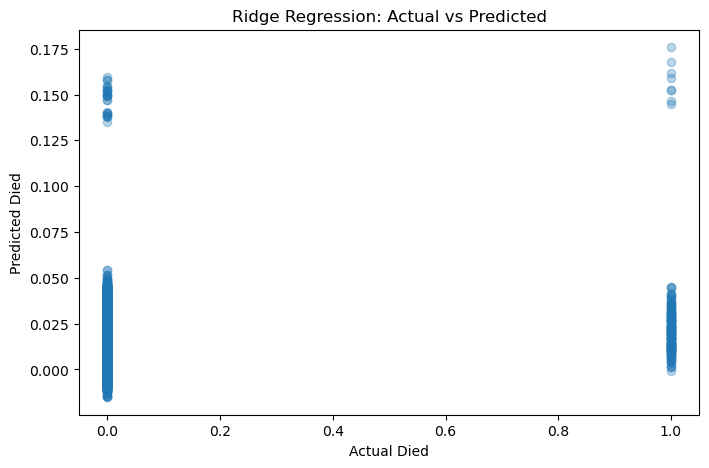

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Died")
plt.ylabel("Predicted Died")
plt.title("Ridge Regression: Actual vs Predicted")

plt.show()

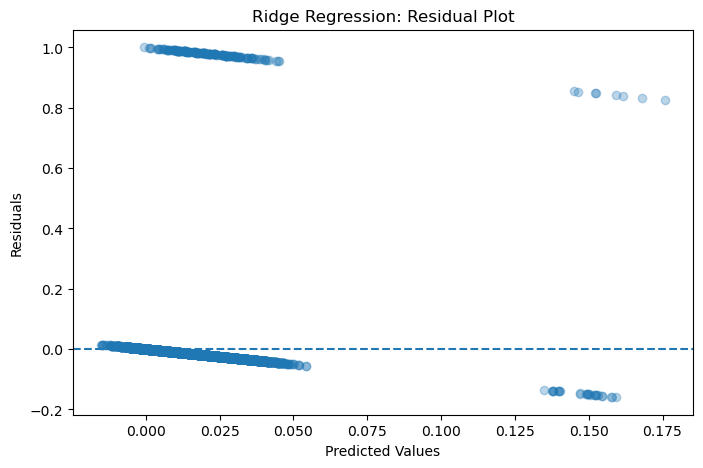

In [14]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Ridge Regression: Residual Plot")

plt.show()